# AAI551 SecondOrder Scenario
Elaine Liu. Illustrative policies and deterministic model outputs, developed with AI assistance. Read docs/model_spec.md for units and limitations. Run all cells from a fresh Python 3.12 kernel.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from dataclasses import replace
from scenario import EconomicScenario, ModelAssumptions
from simulator import ScenarioSimulator
from io_utils import load_scenarios, export_run
from analysis import compare_runs, sensitivity_sweep, crossing_brackets
from visualization import plot_runs
policies = load_scenarios("data/scenarios.json")
runs = {p.name: ScenarioSimulator(p).run() for p in policies}
print(*policies, sep="\n")
print("Fieldwise equality:", policies[0] == replace(policies[0]))

In [2]:
runs["no_policy"].round(4)

,year,adoption,employment,income,consumption,profit,balance,concentration,output,laborIncome,benefits,dividend,aiTax,demand,raw_demand,raw_employment,raw_concentration,demand_clipped,employment_clipped,concentration_clipped,out_of_domain
0,0,0.0000,95.0000,60.0000,45.0000,15.0000,0.0000,60.0000,75.0000,60.0000,0.0000,0.0000,0.0,1.0000,1.0000,95.0000,60.0000,False,False,False,False
1,1,0.1000,91.1215,58.4195,43.8146,19.0924,-0.8018,60.2948,77.2500,57.7576,0.4654,0.1964,0.0,1.0000,1.0000,91.1215,60.2948,False,False,False,False
2,2,0.1900,86.7662,56.5182,42.3887,22.4634,-1.7119,60.8227,78.3979,55.1746,0.9881,0.3556,0.0,0.9889,0.9889,86.7662,60.8227,False,False,False,False
3,3,0.2710,82.7070,54.7046,41.0284,25.2913,-2.5633,61.5428,79.1210,52.7456,1.4752,0.4838,0.0,0.9756,0.9756,82.7070,61.5428,False,False,False,False
4,4,0.3439,79.1239,53.0831,39.8123,27.7036,-3.3164,62.4257,79.6708,50.5917,1.9051,0.5863,0.0,0.9629,0.9629,79.1239,62.4257,False,False,False,False
5,5,0.4095,76.0094,51.6592,38.7444,29.7848,-3.9718,63.4489,80.1365,48.7137,2.2789,0.6666,0.0,0.9516,0.9516,76.0094,63.4489,False,False,False,False
6,6,0.4686,73.3073,50.4112,37.8084,31.5936,-4.5411,64.5942,80.5481,47.0803,2.6031,0.7278,0.0,0.9416,0.9416,73.3073,64.5942,False,False,False,False
7,7,0.5217,70.9567,49.3137,36.9853,33.1731,-5.0367,65.8461,80.9163,45.6564,2.8852,0.7721,0.0,0.9329,0.9329,70.9567,65.8461,False,False,False,False
8,8,0.5695,68.9040,48.3436,36.2577,34.5569,-5.4699,67.1914,81.2456,44.4105,3.1315,0.8015,0.0,0.9252,0.9252,68.9040,67.1914,False,False,False,False
9,9,0.6126,67.1042,47.4816,35.6112,35.7722,-5.8501,68.6189,81.5388,43.3163,3.3475,0.8178,0.0,0.9184,0.9184,67.1042,68.6189,False,False,False,False


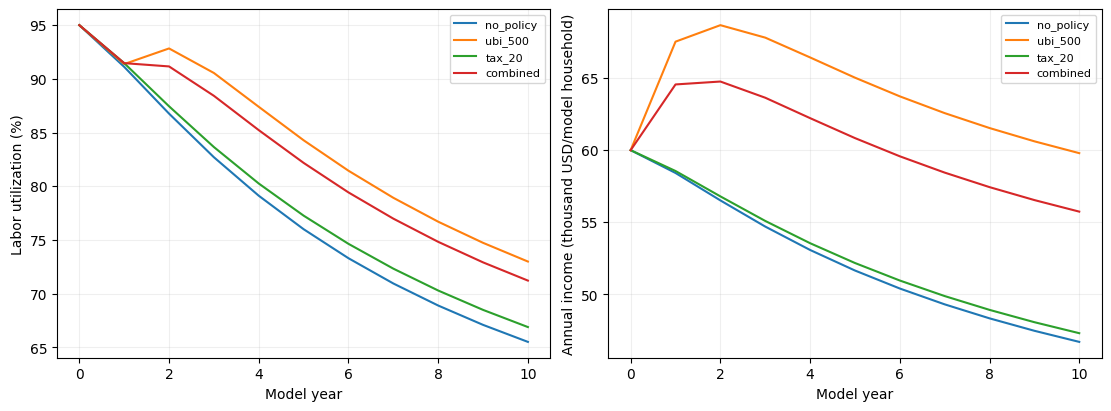

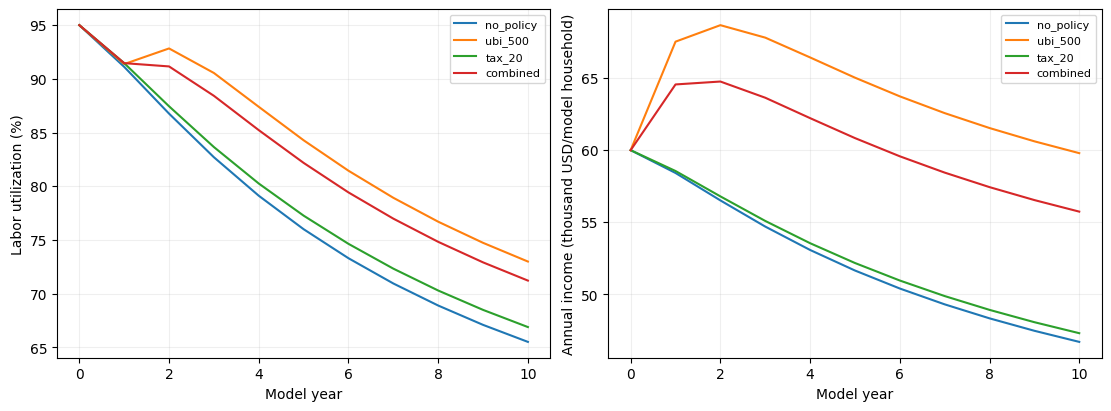

In [3]:
fig = plot_runs(runs)
Path("outputs").mkdir(exist_ok=True)
fig.savefig("outputs/policy_comparison.png", dpi=140)
fig

## Paired comparison and demand feedback
Differences are candidate minus reference. Monetary values are annual thousand USD per model household; labor utilization differences are percentage points.

In [4]:
comparison = compare_runs(runs["no_policy"], runs["ubi_500"])
print(comparison.round(4).to_string(index=False))
no_feedback = ScenarioSimulator(policies[1], ModelAssumptions(feedback=False)).run()
print("UBI final employment, feedback on/off:", runs["ubi_500"].employment.iloc[-1], no_feedback.employment.iloc[-1])

In [5]:
sweep = sensitivity_sweep(policies[0], "ubi", np.linspace(0, 1000, 11))
print(sweep.round(4).to_string(index=False))
substitutions = np.linspace(0, 60, 61)
fixed_target = runs["no_policy"].employment.iloc[-1]
differences = [ScenarioSimulator(replace(policies[1], substitution=float(x))).run().employment.iloc[-1] - fixed_target for x in substitutions]
print("Substitution brackets against fixed reference employment:", crossing_brackets(substitutions, differences))

## Exception handling and meaningful export
Invalid inputs and absent files have different exception types. The export sidecar preserves the configuration.

In [6]:
try:
    EconomicScenario(tax=41)
except ValueError as exc:
    print("Invalid parameter handled:", exc)
try:
    load_scenarios("data/intentional_missing_file.json")
except FileNotFoundError as exc:
    print("Missing input handled:", exc.filename)
sim = ScenarioSimulator(policies[1])
export_run(runs["ubi_500"], sim, "outputs/ubi_500.csv")
restored = pd.read_csv("outputs/ubi_500.csv")
np.testing.assert_allclose(restored.income, runs["ubi_500"].income)
print("CSV round trip verified:", len(restored), "annual rows")

## Research status
A separate 100-run exploratory pilot is saved under outputs/pilot. Run `python -m research.run_pilot` to rebuild. Main E1–E5 experiments, reviewed proofs, literature novelty review and the complete paper remain pending. Results describe this model and its selected assumptions.